# Lab 03 - Glass-Box Interpretability: Linear Probing & Activation Patching

**Goal:** open a CV-screening model and locate *where* a protected attribute is represented and *which* hidden units
causally carry its effect on the decision.

1. Train an MLP on synthetic CV features where historical labels are biased against a gender flag (as in real hiring data).
2. **Linear probe**: can gender be decoded from the hidden layer? (representation question)
3. **Activation patching**: run a counterfactual pair (same CV, gender flipped); patch hidden units from the clean run into the
   corrupted run and measure how much of the logit difference each unit restores (causal question).
4. Ablate the top mediating units and re-measure the counterfactual flip rate.

In [1]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
def show(fig, name):
    fig.tight_layout(); fig.savefig(name, dpi=110); plt.close(fig); display(Image(name))


In [2]:
n = 4000
skills = rng.normal(size=(n, 6))
gender = rng.integers(0, 2, n)                     # 1 = female (protected attribute)
merit = skills[:, :3].sum(1) + 0.5 * skills[:, 3]
y = (merit - 0.9 * gender + rng.normal(scale=0.5, size=n) > 0).astype(np.float32)   # biased historical labels
X = np.hstack([skills, gender[:, None]]).astype(np.float32)
Xt, yt = torch.tensor(X), torch.tensor(y)

class MLP(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = torch.nn.Linear(7, 16); self.l2 = torch.nn.Linear(16, 1)
    def forward(self, x, patch=None):
        h = torch.relu(self.l1(x))
        if patch is not None:
            h = patch(h)
        return self.l2(h).squeeze(-1), h

torch.manual_seed(SEED)
model = MLP()
opt = torch.optim.Adam(model.parameters(), lr=0.02)
for _ in range(400):
    opt.zero_grad()
    loss = F.binary_cross_entropy_with_logits(model(Xt)[0], yt)
    loss.backward(); opt.step()
with torch.no_grad():
    logit, H = model(Xt)
print(f"train accuracy {((logit > 0).float() == yt).float().mean():.3f}")

train accuracy 0.925


In [3]:
# Linear probe on hidden activations (train/test split, logistic regression in torch)
idx = rng.permutation(n); tr, te = idx[:3000], idx[3000:]
probe = torch.nn.Linear(16, 1)
popt = torch.optim.Adam(probe.parameters(), lr=0.05)
g = torch.tensor(gender, dtype=torch.float32)
for _ in range(300):
    popt.zero_grad()
    F.binary_cross_entropy_with_logits(probe(H[tr]).squeeze(-1), g[tr]).backward(); popt.step()
with torch.no_grad():
    acc = ((probe(H[te]).squeeze(-1) > 0).float() == g[te]).float().mean().item()
print(f"gender decodable from hidden layer with probe accuracy {acc:.3f} (chance = 0.5)")

gender decodable from hidden layer with probe accuracy 0.909 (chance = 0.5)


mean logit gap male-female 3.119; counterfactual decision flip rate 0.189
top mediating units: [8, 3, 12] recovery: [0.231, 0.188, 0.144]


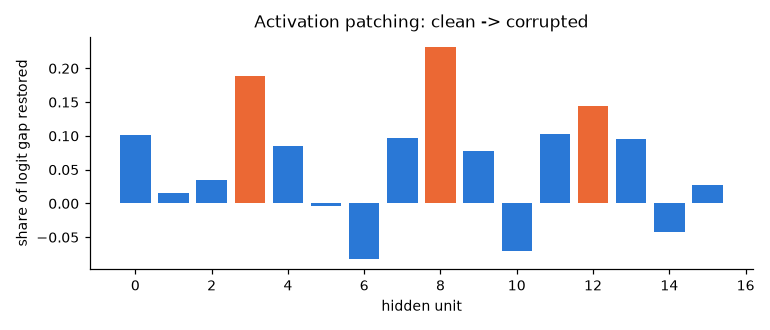

In [4]:
# Counterfactual pairs: identical skills, gender flipped (clean = male, corrupted = female)
Xc = Xt.clone(); Xc[:, 6] = 0
Xf = Xt.clone(); Xf[:, 6] = 1
with torch.no_grad():
    lc, hc = model(Xc); lf, hf = model(Xf)
base_gap = (lc - lf).mean().item()
flip_rate = ((lc > 0) != (lf > 0)).float().mean().item()
print(f"mean logit gap male-female {base_gap:.3f}; counterfactual decision flip rate {flip_rate:.3f}")

recovery = []
for unit in range(16):
    def patch(h, unit=unit):
        h = h.clone(); h[:, unit] = hc[:, unit]; return h
    with torch.no_grad():
        lp, _ = model(Xf, patch=patch)
    recovery.append(((lp - lf).mean() / (lc - lf).mean()).item())
recovery = np.array(recovery)
order = np.argsort(-recovery)
print("top mediating units:", order[:3].tolist(), "recovery:", np.round(recovery[order[:3]], 3).tolist())

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(range(16), recovery, color=[ORANGE if i in order[:3] else BLUE for i in range(16)])
ax.set_xlabel("hidden unit"); ax.set_ylabel("share of logit gap restored"); ax.set_title("Activation patching: clean -> corrupted")
show(fig, "lab03_patching.png")

In [5]:
# Ablate (mean-ablate) the top-3 mediating units and re-measure the counterfactual flip rate
top = torch.tensor(order[:3])
means = H.mean(0)
def ablate(h):
    h = h.clone(); h[:, top] = means[top]; return h
with torch.no_grad():
    lc2, _ = model(Xc, patch=ablate); lf2, _ = model(Xf, patch=ablate)
flip_after = ((lc2 > 0) != (lf2 > 0)).float().mean().item()
acc_after = (((lc2 > 0).float() == yt).float().mean()).item()
print(f"flip rate {flip_rate:.3f} -> {flip_after:.3f} after ablating units {order[:3].tolist()}")
print(f"accuracy against (biased) historical labels after ablation: {acc_after:.3f}")

flip rate 0.189 -> 0.084 after ablating units [8, 3, 12]
accuracy against (biased) historical labels after ablation: 0.855


## Takeaways
* A high probe accuracy shows the attribute is **represented**; activation patching shows which units **causally** carry it
  into the decision - representation is not the same as use.
* Mean-ablating a handful of mediating units cuts the counterfactual flip rate. Mechanistic evidence like this belongs
  in the technical documentation of a high-risk system (EU AI Act Art. 11 & Annex IV), next to black-box fairness metrics.